In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import directories

import matplotlib.pyplot as plt
import numpy as np
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import figure_settings
import seaborn as sns
import pandas as pd

from scipy.stats import gaussian_kde
from matplotlib.offsetbox import AnchoredText

import matplotlib
matplotlib.rcParams.update(matplotlib.rcParamsDefault)
plt.rcParams.update(figure_settings.new_rcParams())

In [7]:
res_pseob = pd.read_csv(directories.basedir / "gw250114_pseobnr/pSEOBNRv5PHM_pesummary.dat",sep="\s+")

# 2D hierarchical results
samps = np.load(directories.basedir / "gw250114_pseobnr/hierarchical/pSEOB/pseob_hier_pop.npz")
df220_hier = samps["pop_domega_220"]
dtau220_hier = samps["pop_dtau_220"]

# Data for the remnant properties
remnant_dict = np.load(directories.basedir / "gw250114_pseobnr/pseob_remnant_samples.npz")

In [8]:
color_event = figure_settings.color_palette['primary']
color_hier = "#BA0C2F"

# We run the original analysis with wider priors 
# domega440, dtau440 ~ [-0.8, 4.0], but report our main
# results under a narrower prior ~ [-0.8, 0.8] for the
# reasons discussed in the Supplemental Material. 
# Rather than rerunning with the narrower prior, 
# we are just cutting the samples afterwards, 
# since for uniform priors these are equivalent.

idx = np.where(
    (res_pseob["dtau440"] < 0.8) &
    (res_pseob["domega440"] < 0.8)
)[0]

df220 = res_pseob["domega220"][idx]
df440 = res_pseob["domega440"][idx]
dtau220 = res_pseob["dtau220"][idx]
dtau440 = res_pseob["dtau440"][idx]

axes_map = {
    'df220': 0,
    'dtau220': 1,
    'df440': 2,
}

data = [
    (df220, axes_map['df220'], color_event, r'$\delta \hat{f}_{\mathrm{220}}$'),
    (df220_hier, axes_map['df220'], color_hier, None),
    (dtau220, axes_map['dtau220'], color_event, r'$\delta \hat \tau_{\mathrm{220}}$'),
    (dtau220_hier, axes_map['dtau220'], color_hier, None),
    (df440, axes_map['df440'], color_event, r'$\delta \hat{f}_{\mathrm{440}}$'),
]

In [9]:
from matplotlib.legend_handler import HandlerLine2D

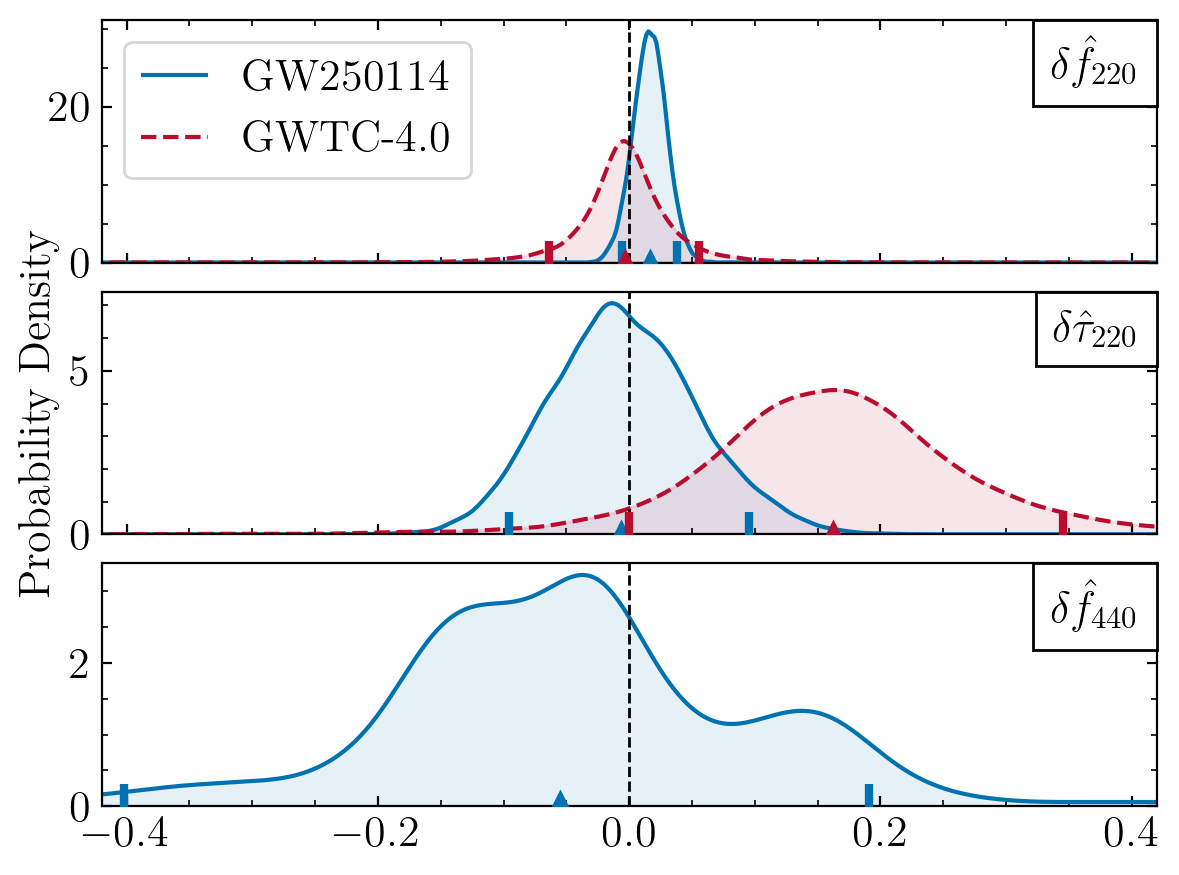

In [10]:
x, y = figure_settings.new_rcParams(width='column', aspect_ratio=2)['figure.figsize']

with plt.rc_context({'figure.figsize': (x, 1.5 * y)}):
    fig, axs = plt.subplots(nrows=3, sharex=True)
    
    for samples, ax_idx, color, label in data:

        kde = gaussian_kde(samples)
        x = np.linspace(-0.8, 0.8, 1000)
        y = kde(x)

        if label is not None:
            axs[ax_idx].plot(x, y, color=color)
            axs[ax_idx].fill_between(x, y, 0.0, color=color, alpha=0.1)

            anchored_label = AnchoredText(
                label,
                loc='upper right',
                #prop=dict(size=18),
                frameon=True,
                pad=0.4,
                borderpad=0.0,
            )
            anchored_label.patch.set_facecolor('white')
            #anchored_label.patch.set_alpha(0.85)
            anchored_label.patch.set_edgecolor('k')
            #anchored_label.patch.set_linewidth(0.6)

            axs[ax_idx].add_artist(anchored_label)

        else:
            axs[ax_idx].plot(x, y, color=color, ls="--")
            axs[ax_idx].fill_between(x, y, 0.0, color=color, alpha=0.1)

        lkws = {'ls': 'none', 'c': color, 'zorder': 3}
        axs[ax_idx].plot([np.percentile(samples, 5), np.percentile(samples, 95)], [0.0,0.0], marker='|', ms=16, mew=3, mfc='none', **lkws)
        axs[ax_idx].plot(np.median(samples), 0.05, marker='^', ms=8, **lkws)

    for ax in axs:
        ax.grid(visible=False)
        ax.set_xlim(-0.42, 0.42)
        ax.set_ylim(0)
        ax.tick_params(axis='y', right=True, which="both")
        ax.tick_params(axis='x', bottom=True, labelbottom=True)
        ax.axvline(0.0, lw = 1.0, color = "k", ls = "--")

    for ax in axs[:-1]:  # All but the last axis
        ax.tick_params(labelbottom=False)

    axs[0].tick_params(axis='x', top=True, which="both")
    axs[1].set_ylabel("Probability Density")

    # Custom handler to respect lw
    class ThinLineHandler(HandlerLine2D):
        def create_artists(self, legend, orig_handle,
                           xdescent, ydescent, width, height, fontsize, trans):
            # Draw line exactly at original linewidth
            line = mlines.Line2D([0, width], [height/2, height/2],
                                 lw=orig_handle.get_linewidth(),
                                 linestyle=orig_handle.get_linestyle(),
                                 color=orig_handle.get_color(),
                                 solid_capstyle='butt',
                                 transform=trans)
            return [line]

    # Create Line2D handles (lw can now be tiny)
    line1 = mlines.Line2D([], [], color=color_event, linestyle='-', label='GW250114')
    line2 = mlines.Line2D([], [], color=color_hier, linestyle='--', label='GWTC-4.0')

    # Legend with custom handler
    axs[0].legend([line1, line2], ['GW250114', 'GWTC-4.0'],
              handler_map={mlines.Line2D: ThinLineHandler()},
              loc='upper left')

    plt.subplots_adjust(hspace=0.12) 

    plt.savefig("../figures/ridgeline_domega_dtau.pdf", bbox_inches='tight', dpi=300)
    plt.show()

In [11]:
def get_gr_quantile(d):
    kde = gaussian_kde(d.values.T)
    p = kde(d.values.T)
    gr = [0] * len(d.columns)
    p0 = kde(gr)
    return len(p[p > p0]) / len(p)

In [12]:
data = pd.DataFrame({"df220": df220, "dtau220": dtau220})
gr_quantile_event = get_gr_quantile(data) * 100

print(gr_quantile_event)

54.227257355427795


In [13]:
# From /home/lorenzo.pompili/tgr/O4a/pseobnrv5phm/scripts_O4a_macros_figures/hierarchical_results_2D/hierarchical_2D_macros.ipynb
gr_quantile_hier = 85.1

In [14]:
def ComputeSymCIedges(samples, ci=0.9):
    med = np.median(samples)
    lo = np.percentile(samples, 100.0 * (1-ci)*0.5)
    hi = np.percentile(samples, 100.0 * (1-(1-ci)*0.5))
    return med, hi, lo

In [15]:
def make_latex_macro_cmd(cmd_name, data, review_status):
    median, upper, lower = ComputeSymCIedges(data, ci=0.9)
    median_fmt = f"{median:.2f}"
    upper_fmt = f"{upper - median:.2f}"
    lower_fmt = f"{median - lower:.2f}"

    if median_fmt == '-0.00':
        median_fmt = '0.00'

    if review_status == "reviewed":
        return f"\\newcommand{{\\{cmd_name}}}{{{median_fmt}^{{+{upper_fmt}}}_{{-{lower_fmt}}}}}"
    else:
        return f"\\newcommand{{\\{cmd_name}}}{{\\{review_status}{{{median_fmt}^{{+{upper_fmt}}}_{{-{lower_fmt}}}}}}}"

In [16]:
def make_latex_macro_cmd_1f(cmd_name, data, review_status):
    median, upper, lower = ComputeSymCIedges(data, ci=0.9)
    median_fmt = f"{median:.1f}"
    upper_fmt = f"{upper - median:.1f}"
    lower_fmt = f"{median - lower:.1f}"

    if median_fmt == '-0.00':
        median_fmt = '0.00'

    if review_status == "reviewed":
        return f"\\newcommand{{\\{cmd_name}}}{{{median_fmt}^{{+{upper_fmt}}}_{{-{lower_fmt}}}}}"
    else:
        return f"\\newcommand{{\\{cmd_name}}}{{\\{review_status}{{{median_fmt}^{{+{upper_fmt}}}_{{-{lower_fmt}}}}}}}"

In [17]:
def make_latex_macro_cmd_0f(cmd_name, data, review_status):
    median, upper, lower = ComputeSymCIedges(data, ci=0.9)
    median_fmt = f"{median:.0f}"
    upper_fmt = f"{upper - median:.0f}"
    lower_fmt = f"{median - lower:.0f}"

    if median_fmt == '-0.00':
        median_fmt = '0.00'

    if review_status == "reviewed":
        return f"\\newcommand{{\\{cmd_name}}}{{{median_fmt}^{{+{upper_fmt}}}_{{-{lower_fmt}}}}}"
    else:
        return f"\\newcommand{{\\{cmd_name}}}{{\\{review_status}{{{median_fmt}^{{+{upper_fmt}}}_{{-{lower_fmt}}}}}}}"

In [18]:
with open("../macros/pSEOB_macros.tex", "w") as f:

    f.write("% Macros for pSEOB" + "\n\n")

    # Event (df, dtau)

    cmd = make_latex_macro_cmd(
        cmd_name="EventpSEOBFreqFourFour", data=df440, review_status="reviewed"
    )
    f.write(cmd + "\n")

    cmd = make_latex_macro_cmd(
        cmd_name="EventpSEOBTauFourFour", data=dtau440, review_status="reviewed"
    )
    f.write(cmd + "\n")

    cmd = make_latex_macro_cmd(
        cmd_name="EventpSEOBFreqTwoTwo", data=df220, review_status="reviewed"
    )
    f.write(cmd + "\n")

    cmd = make_latex_macro_cmd(
        cmd_name="EventpSEOBTauTwoTwo", data=dtau220, review_status="reviewed"
    )
    f.write(cmd + "\n")

    # Hierarchical (df, dtau)

    cmd = make_latex_macro_cmd(
        cmd_name="HierpSEOBFreqTwoTwo", data=df220_hier, review_status="reviewed"
    )
    f.write(cmd + "\n")

    cmd = make_latex_macro_cmd(
        cmd_name="HierpSEOBTauTwoTwo", data=dtau220_hier, review_status="reviewed"
    )
    f.write(cmd + "\n")

    ### Event (f, tau)

    cmd = make_latex_macro_cmd_0f(
        cmd_name="EventpSEOBFreqFourFourFull", data=remnant_dict["f_pSEOB_440"], review_status="reviewed"
    )
    f.write(cmd + "\n")

    cmd = make_latex_macro_cmd_1f(
        cmd_name="EventpSEOBTauFourFourFull", data=1e3 * remnant_dict["tau_pSEOB_440"], review_status="reviewed"
    )
    f.write(cmd + "\n")

    cmd = make_latex_macro_cmd_1f(
        cmd_name="EventpSEOBFreqTwoTwoFull", data=remnant_dict["f_pSEOB_220"], review_status="reviewed"
    )
    f.write(cmd + "\n")

    cmd = make_latex_macro_cmd(
        cmd_name="EventpSEOBTauTwoTwoFull", data=1e3 * remnant_dict["tau_pSEOB_220"], review_status="reviewed"
    )
    f.write(cmd + "\n")

    ### GR quantile: event
    review_status = "reviewed"
    cmd_name="EventpSEOBQuantile"
    cmd = f"\\newcommand{{\\{cmd_name}}}{{{gr_quantile_event:.1f}\%}}"

    f.write(cmd + "\n")

    ### GR quantile: hierarchical
    review_status = "reviewed"
    cmd_name="HierpSEOBQuantile"
    cmd = f"\\newcommand{{\\{cmd_name}}}{{{gr_quantile_hier:.1f}\%}}"

    f.write(cmd + "\n")

In [19]:
import bilby

res = bilby.read_in_result(directories.basedir / "gw250114_bilby/bilby-NRSur7dq4_prod/pesummary/samples/bilby-NRSur7dq4_prod_bilby-NRSur7dq4_prod_data0_1420878141-222656_analysis_H1L1_merge_result.hdf5")

In [20]:
samples = res.posterior["theta_jn"]

In [21]:
folded_samples = np.where(samples <= np.pi / 2, samples, np.pi - samples)

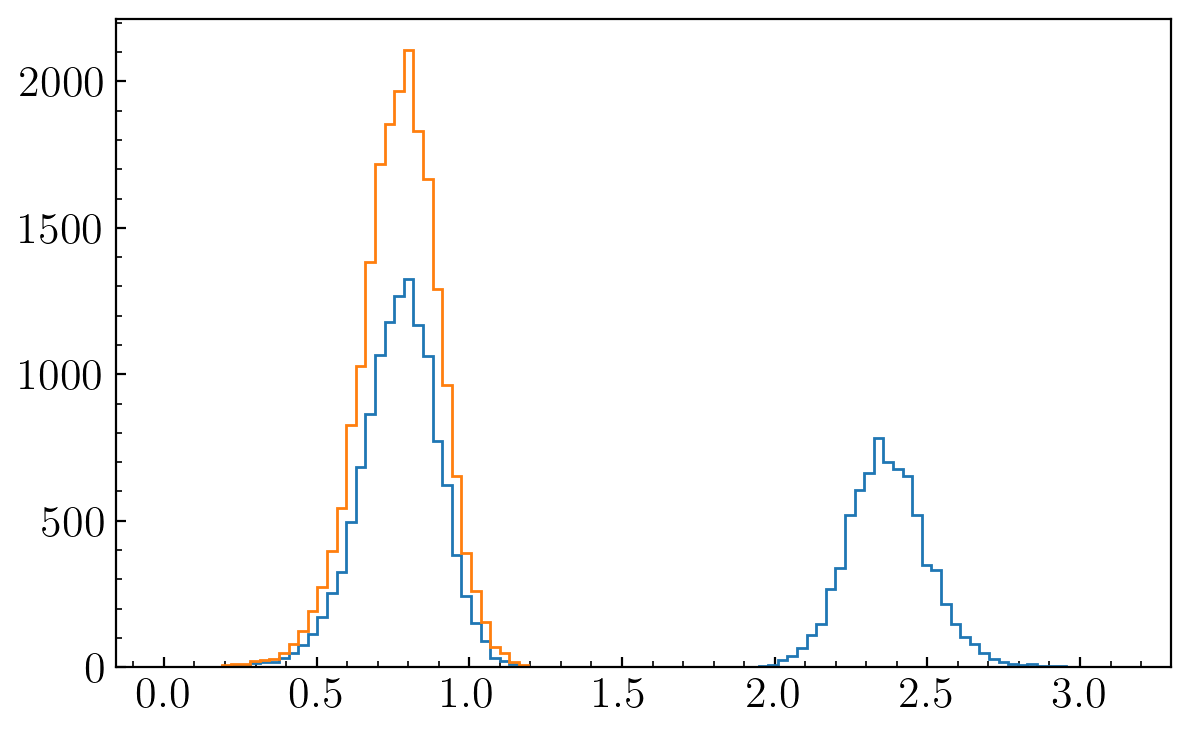

In [22]:
bins = np.linspace(0, np.pi, 101)
plt.hist(samples, bins = bins, histtype="step");
plt.hist(folded_samples, bins = bins, histtype="step");
plt.show()

In [23]:
with open("../macros/pSEOB_macros.tex", "a") as f:

    cmd = make_latex_macro_cmd(
        cmd_name="EventThetaJNFolded", data=folded_samples, review_status="reviewed"
    )
    f.write(cmd + "\n")